# Detecção de fraude em transações
## Avaliação temporal, capacidade operacional e exposição financeira

**Status do estudo — exploratório**

Este estudo compara modelos de classificação para priorizar transações para revisão. A decisão considera a qualidade do ranking, a capacidade da equipe e o valor financeiro sinalizado.

### Pergunta de negócio
Qual modelo identifica mais fraudes e maior exposição financeira dentro da capacidade disponível de revisão?

### Critério de decisão
O padrão deste experimento seleciona o modelo pela maior Average Precision (AP) na validação. A capacidade de referência é de 100 análises na janela de validação. Ambos podem ser configurados na próxima seção.

### Leitura do estudo
1. Configuração e qualidade dos dados
2. Perfil das transações e premissas
3. Separação temporal e treinamento
4. Comparação operacional, seleção e estabilidade temporal
5. Avaliação exploratória, exposição financeira e resumo executivo
6. Diagnóstico de erros e interpretação
7. Próximos critérios de validação

### Limites de interpretação
- A base cobre aproximadamente 48 horas. As horas são relativas ao início da amostra.
- A exploração inicial abrange a base completa e o teste já foi consultado. A confirmação das melhorias exige um novo período reservado.
- A remoção de duplicatas exatas é uma hipótese de limpeza a confirmar com a origem dos dados.
- O ranking top-K e o corte por score produzem políticas diferentes. O corte pode gerar volumes variáveis e incluir empates.
- Valores sinalizados representam exposição. A perda evitada depende da intervenção e de sua eficácia.
- Scores precisam de avaliação de calibração antes de serem usados como probabilidades.

## Configuração e reprodução
Execute as células em ordem após reiniciar o kernel. Registre as versões apresentadas e mantenha o CSV na mesma pasta do notebook.

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

SEMENTE = 42
CAPACIDADES = [25, 50, 100, 200, 500]
CAPACIDADE_REVISAO = 100
CRITERIO_SELECAO = "AP"
CUSTO_POR_REVISAO = None
CUSTO_ADICIONAL_POR_FALSO_ALERTA = None
N_JANELAS_ESTABILIDADE = 4
MODELOS_ESTABILIDADE = ["logistica_balanceada", "hgb_balanceado", "random_forest"]

# Parâmetros validados antes de carregar os dados e treinar os modelos.
CRITERIOS_VALIDOS = ["AP", "fraudes_identificadas", "valor_identificado"]
if CRITERIO_SELECAO not in CRITERIOS_VALIDOS:
    raise ValueError(f"CRITERIO_SELECAO deve ser um de {CRITERIOS_VALIDOS}.")
if not all(isinstance(k, int) and k >= 1 for k in CAPACIDADES + [CAPACIDADE_REVISAO]):
    raise ValueError("Capacidades devem ser números inteiros positivos.")
for nome_custo, custo in [("CUSTO_POR_REVISAO", CUSTO_POR_REVISAO),
                          ("CUSTO_ADICIONAL_POR_FALSO_ALERTA", CUSTO_ADICIONAL_POR_FALSO_ALERTA)]:
    if custo is not None and custo < 0:
        raise ValueError(f"{nome_custo} não pode ser negativo.")
if not isinstance(N_JANELAS_ESTABILIDADE, int) or N_JANELAS_ESTABILIDADE < 2:
    raise ValueError("N_JANELAS_ESTABILIDADE deve ser um inteiro maior ou igual a 2.")


def fmt_br(valor, casas=2):
    """Número no padrão brasileiro: 1.234,56."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")


def fmt_int(valor):
    """Contagem inteira no padrão brasileiro: 1.234."""
    return fmt_br(round(valor), 0)


print(f"Python {sys.version.split()[0]} | pandas {pd.__version__}")
print(f"NumPy {np.__version__} | scikit-learn {sklearn.__version__}")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#334155",
    "text.color": "#0f172a",
    "font.size": 10,
    "savefig.bbox": "tight",
})

Python 3.14.7 | pandas 3.0.2
NumPy 2.4.4 | scikit-learn 1.8.0


## Qualidade e estrutura dos dados
Verificamos colunas, classes, valores ausentes e duplicatas antes da modelagem.

In [2]:
df = pd.read_csv("creditcard.csv")

# Validação estrutural: interrompe a execução se a base não tiver o formato esperado.
colunas_esperadas = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount", "Class"]
faltantes = sorted(set(colunas_esperadas) - set(df.columns))
if faltantes:
    raise ValueError(f"Colunas ausentes: {faltantes}")
nao_numericas = [c for c in colunas_esperadas if not pd.api.types.is_numeric_dtype(df[c])]
if nao_numericas:
    raise TypeError(f"Colunas não numéricas: {nao_numericas}")
ausentes = int(df[colunas_esperadas].isna().sum().sum())
infinitos = int(np.isinf(df[colunas_esperadas].to_numpy(dtype=float)).sum())
if ausentes or infinitos:
    raise ValueError(f"Base com {ausentes} valores ausentes e {infinitos} infinitos.")
if not set(df["Class"].unique()) <= {0, 1}:
    raise ValueError("Class deve conter apenas 0 e 1.")
if (df["Amount"] < 0).any() or (df["Time"] < 0).any():
    raise ValueError("Amount e Time não podem ser negativos.")
print(f"Base validada: {fmt_int(len(df))} linhas e {df.shape[1]} colunas, sem ausentes ou infinitos.")

Base validada: 284.807 linhas e 31 colunas, sem ausentes ou infinitos.


In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print(df.shape)
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True)* 100)
print(df[["Time", "Amount"]].describe())

print(df.isna().sum().sum())

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64
                Time         Amount
count  284807.000000  284807.000000
mean    94813.859575      88.349619
std     47488.145955     250.120109
min         0.000000       0.000000
25%     54201.500000       5.600000
50%     84692.000000      22.000000
75%    139320.500000      77.165000
max    172792.000000   25691.160000
0


In [5]:
# Duplicatas exatas 
print("Linhas duplicadas:", df.duplicated().sum())
print("Fraudes entre as duplicadas : ",  df[df.duplicated()]['Class'].sum())

Linhas duplicadas: 1081


Fraudes entre as duplicadas :  19


## Perfil das transações
As distribuições ajudam a formular hipóteses. As observações desta exploração precisam de confirmação em outros períodos.

In [6]:
# Valor da transação por classe (mediana e quantis)

print(df.groupby("Class")['Amount'].describe())

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [7]:
# Transações com valor Zero

zeros =df["Amount"] == 0
print("Amount == 0:", zeros.sum(), '| fraude entre elas:', df.loc[zeros, "Class"].sum())


Amount == 0: 1825 | fraude entre elas: 27


In [8]:
#Taxa de fraude por hora relativa
hora = (df["Time"]// 3600) % 24
taxa_hora = df.groupby(hora)['Class'].agg(fraudes='sum', total= 'size')
taxa_hora["taxa_%"] = taxa_hora["fraudes"] / taxa_hora["total"] * 100

print(taxa_hora)


      fraudes  total    taxa_%
Time                          
0.0         6   7695  0.077973
1.0        10   4220  0.236967
2.0        57   3328  1.712740
3.0        17   3492  0.486827
4.0        23   2209  1.041195
5.0        11   2990  0.367893
6.0         9   4101  0.219459
7.0        23   7243  0.317548
8.0         9  10276  0.087583
9.0        16  15838  0.101023
10.0        8  16598  0.048199
11.0       53  16856  0.314428
12.0       17  15420  0.110246
13.0       17  15365  0.110641
14.0       23  16570  0.138805
15.0       26  16461  0.157949
16.0       22  16453  0.133714
17.0       29  16166  0.179389
18.0       33  17039  0.193673
19.0       19  15649  0.121414
20.0       18  16756  0.107424
21.0       16  17703  0.090380
22.0        9  15441  0.058286
23.0       21  10938  0.191991


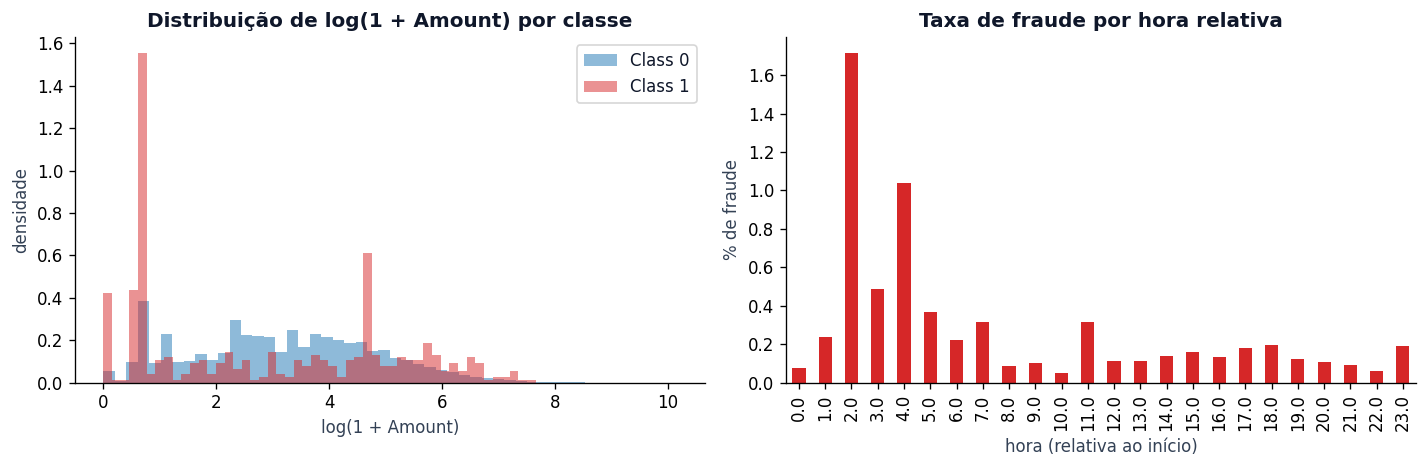

In [9]:
#Visão em grafico
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for classe, cor in [(0, "tab:blue"), (1, "tab:red")]:
    axes[0].hist(np.log1p(df.loc[df["Class"] == classe, "Amount"]), bins=50,
                 density=True, alpha=0.5, color=cor, label=f"Class {classe}")
axes[0].set(title="Distribuição de log(1 + Amount) por classe", xlabel="log(1 + Amount)", ylabel="densidade")
axes[0].legend()

taxa_hora["taxa_%"].plot(kind="bar", ax=axes[1], color="tab:red")
axes[1].set(title="Taxa de fraude por hora relativa", xlabel="hora (relativa ao início)", ylabel="% de fraude")
plt.tight_layout()
plt.show()

In [10]:
dia = df['Time'] // 86400 
print(pd.crosstab(hora, dia, values=df["Class"], aggfunc="sum").loc[[2.0, 4.0, 11.0]])


Time  0.0  1.0
Time          
2.0    21   36
4.0     6   17
11.0   43   10


## Separação temporal
Os registros são ordenados pelo tempo. Os cortes se aproximam de 70% para treino, 15% para validação e 15% para teste, mantendo timestamps iguais no mesmo conjunto.

O treino ajusta os modelos. A validação orienta a seleção e o limiar. O período final mantém caráter exploratório porque já foi analisado em versões anteriores.


In [11]:
df_limpo = df.drop_duplicates().sort_values('Time', kind='stable').reset_index(drop=True)
print("Após remover duplicatas: ", df_limpo.shape, "| FRAUDES: ", df_limpo['Class'].sum())



Após remover duplicatas:  (283726, 31) | FRAUDES:  473


In [12]:
# Cortes aproximados de 70/15/15%, mantendo timestamps iguais juntos.
n = len(df_limpo)
corte_treino = df_limpo.iloc[int(n * 0.70)]["Time"]
corte_validacao = df_limpo.iloc[int(n * 0.85)]["Time"]
treino = df_limpo.loc[df_limpo["Time"] < corte_treino].copy()
validacao = df_limpo.loc[
    (df_limpo["Time"] >= corte_treino) & (df_limpo["Time"] < corte_validacao)
].copy()
teste = df_limpo.loc[df_limpo["Time"] >= corte_validacao].copy()

for nome, parte in [("treino", treino), ("validacao", validacao), ("teste", teste)]:
    if parte.empty or parte["Class"].nunique() != 2:
        raise ValueError(f"{nome}: período vazio ou sem as duas classes.")
    print(f"{nome}: {len(parte)} transações | {parte['Class'].sum()} fraudes "
          f"| taxa {parte['Class'].mean():.3%} "
          f"| horas {parte['Time'].min()/3600:.2f} a {parte['Time'].max()/3600:.2f}")
assert treino["Time"].max() < validacao["Time"].min()
assert validacao["Time"].max() < teste["Time"].min()

# Capacidades conferidas aqui, antes do treinamento.
if max(CAPACIDADES + [CAPACIDADE_REVISAO]) > len(validacao):
    raise ValueError("Há capacidades maiores que o número de transações da validação.")
duracao_validacao_h = (validacao["Time"].max() - validacao["Time"].min()) / 3600
duracao_teste_h = (teste["Time"].max() - teste["Time"].min()) / 3600
print(f"Duração das janelas: validação {fmt_br(duracao_validacao_h, 1)} h | "
      f"teste {fmt_br(duracao_teste_h, 1)} h")

treino: 198607 transações | 366 fraudes | taxa 0.184% | horas 0.00 a 36.92
validacao: 42558 transações | 55 fraudes | taxa 0.129% | horas 36.92 a 42.03
teste: 42561 transações | 52 fraudes | taxa 0.122% | horas 42.03 a 48.00
Duração das janelas: validação 5,1 h | teste 6,0 h


## Treinamento dos modelos
A padronização da regressão logística é ajustada dentro do pipeline com os dados de treino.

In [13]:
from sklearn.dummy              import DummyClassifier
from sklearn.linear_model       import LogisticRegression
from sklearn.pipeline           import make_pipeline
from sklearn.preprocessing      import StandardScaler
from sklearn.metrics            import average_precision_score, roc_auc_score
from sklearn.ensemble           import HistGradientBoostingClassifier
from sklearn.ensemble           import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, confusion_matrix

In [14]:
#Features: tudo menos Time(só serve para ordenar) e Class (é o alvo)

features = [c for c in df_limpo.columns if c not in ('Time', 'Class')]
x_treino, y_treino = treino[features], treino ['Class']
x_validacao, y_validacao = validacao[features], validacao["Class"]


modelos ={
    'dummy': DummyClassifier(strategy='prior'),
    'logistica': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'logistica_balanceada': make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")
    ),
}


def fraudes_no_topo(y, score, k):
    """Quantas fraudes aparecem entre as k transações com maior score."""
    topo = np.argsort(-score, kind="stable")[:k]
    return y.to_numpy()[topo].sum()

print(f"Referência AP (taxa de fraude na validação): {y_validacao.mean():.4f}\n")
for nome, modelo in modelos.items():
    modelo.fit(x_treino, y_treino)
    score = modelo.predict_proba(x_validacao)[:, 1]
    print(f"{nome:22} | AP: {average_precision_score(y_validacao, score):.3f} "
          f"| ROC-AUC: {roc_auc_score(y_validacao, score):.3f} "
          f"| fraudes no top 100: {fraudes_no_topo(y_validacao, score, 100)}/{y_validacao.sum()}")

Referência AP (taxa de fraude na validação): 0.0013

dummy                  | AP: 0.001 | ROC-AUC: 0.500 | fraudes no top 100: 0/55


logistica              | AP: 0.779 | ROC-AUC: 0.982 | fraudes no top 100: 48/55


logistica_balanceada   | AP: 0.837 | ROC-AUC: 0.981 | fraudes no top 100: 47/55


In [15]:
modelos["hgb"] = HistGradientBoostingClassifier(random_state=SEMENTE)
modelos["hgb"].fit(x_treino, y_treino)
scores = {
    nome: modelo.predict_proba(x_validacao)[:, 1]
    for nome, modelo in modelos.items() if nome != "dummy"
}
total = int(y_validacao.sum())


In [16]:
extras = {
    "hgb_balanceado": HistGradientBoostingClassifier(
        class_weight="balanced", learning_rate=0.05, max_iter=300, random_state=SEMENTE
    ),
    "random_forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
        n_jobs=-1, random_state=SEMENTE
    ),
}

for nome, m in extras.items():
    m.fit(x_treino, y_treino)
    s = m.predict_proba(x_validacao)[:, 1]
    modelos[nome] = m
    scores[nome] = s
    print(f"{nome:22} | AP: {average_precision_score(y_validacao, s):.3f} "
          f"| top 50: {fraudes_no_topo(y_validacao, s, 50)}/{total} "
          f"| top 100: {fraudes_no_topo(y_validacao, s, 100)}/{total}")

hgb_balanceado         | AP: 0.839 | top 50: 42/55 | top 100: 47/55


random_forest          | AP: 0.875 | top 50: 45/55 | top 100: 48/55


## Comparação operacional na validação
Cada modelo é avaliado com as mesmas capacidades de revisão.

| Indicador | Interpretação |
|---|---|
| AP | Qualidade do ranking ao longo dos limiares |
| Precisão | Percentual de alertas que são fraudes |
| Recall | Percentual das fraudes que recebe alerta |
| Valor identificado | Soma dos valores das fraudes sinalizadas |
| Falsos alertas | Transações legítimas encaminhadas para revisão |
| Análises por fraude | Esforço de revisão para cada fraude encontrada |
| Alertas por hora | Volume de revisão por hora da janela de validação |

Os gráficos apresentam pontos de capacidade definidos no experimento. A decisão deve considerar a duração da janela e a capacidade real da equipe.

,modelo,AP,alertas,alertas_por_hora,fraudes_identificadas,falsos_alertas,precisao_%,recall_%,valor_identificado,valor_identificado_%,analises_por_fraude
10,hgb,0.59,25,4.89,21,4,84.0,38.18,5705.49,67.95,1.19
15,hgb_balanceado,0.84,25,4.89,25,0,100.0,45.45,4006.94,47.72,1.00
0,logistica,0.78,25,4.89,24,1,96.0,43.64,2805.12,33.41,1.04
5,logistica_balanceada,0.84,25,4.89,25,0,100.0,45.45,2927.62,34.87,1.00
20,random_forest,0.87,25,4.89,25,0,100.0,45.45,2368.43,28.21,1.00
11,hgb,0.59,50,9.78,38,12,76.0,69.09,7541.51,89.82,1.32
16,hgb_balanceado,0.84,50,9.78,42,8,84.0,76.36,6996.04,83.32,1.19
1,logistica,0.78,50,9.78,37,13,74.0,67.27,6466.75,77.02,1.35
6,logistica_balanceada,0.84,50,9.78,42,8,84.0,76.36,7991.55,95.18,1.19
21,random_forest,0.87,50,9.78,45,5,90.0,81.82,8232.03,98.05,1.11


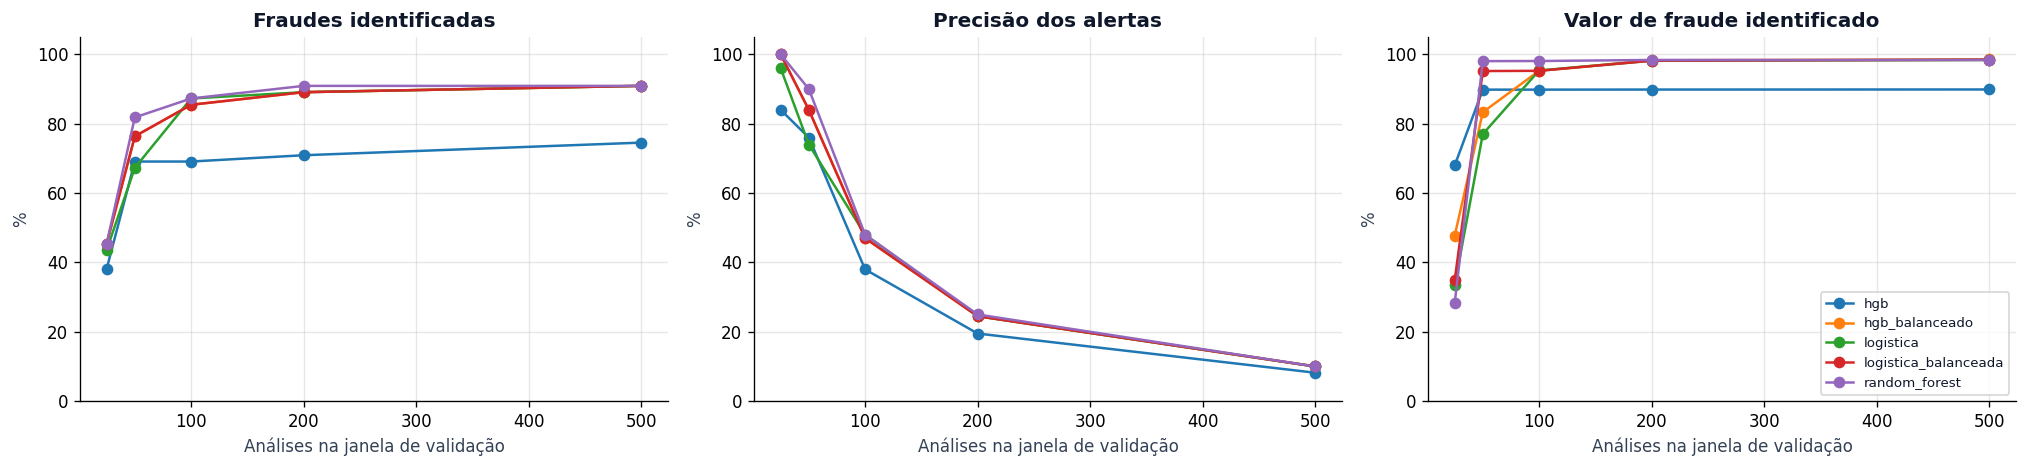

In [17]:
rotulos = y_validacao.to_numpy()
valores = validacao["Amount"].to_numpy()
total_fraudes = int(rotulos.sum())
valor_fraudes = valores[rotulos == 1].sum()
capacidades = sorted(set(CAPACIDADES + [CAPACIDADE_REVISAO]))
# A AP não depende da capacidade: calculada uma vez por modelo.
ap_por_modelo = {nome: average_precision_score(y_validacao, score) for nome, score in scores.items()}
linhas = []
for nome, score in scores.items():
    ordem = np.argsort(-score, kind="stable")
    for capacidade in capacidades:
        indices = ordem[:capacidade]
        mascara = rotulos[indices] == 1
        acertos = int(mascara.sum())
        valor = valores[indices][mascara].sum()
        linhas.append({
            "modelo": nome,
            "AP": ap_por_modelo[nome],
            "alertas": capacidade,
            "alertas_por_hora": capacidade / duracao_validacao_h,
            "fraudes_identificadas": acertos,
            "falsos_alertas": capacidade - acertos,
            "precisao_%": 100 * acertos / capacidade,
            "recall_%": 100 * acertos / total_fraudes,
            "valor_identificado": valor,
            "valor_identificado_%": 100 * valor / valor_fraudes if valor_fraudes else np.nan,
            "analises_por_fraude": capacidade / acertos if acertos else np.nan,
        })
comparacao = pd.DataFrame(linhas)
display(comparacao.sort_values(["alertas", "modelo"]).round(2))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for nome, grupo in comparacao.groupby("modelo"):
    for eixo, coluna in zip(axes, ["recall_%", "precisao_%", "valor_identificado_%"]):
        eixo.plot(grupo["alertas"], grupo[coluna], marker="o", label=nome)
        eixo.set_title({"recall_%": "Fraudes identificadas", "precisao_%": "Precisão dos alertas", "valor_identificado_%": "Valor de fraude identificado"}[coluna])
        eixo.set_xlabel("Análises na janela de validação")
        eixo.set_ylabel("%")
        eixo.set_ylim(0, 105)
        eixo.grid(alpha=0.3)
axes[-1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Seleção e avaliação exploratória
O modelo e o limiar são escolhidos usando a validação. Os resultados abaixo descrevem o período de teste já consultado.

In [18]:
# Critério definido na validação. Teste já explorado anteriormente.
candidatos = comparacao.loc[comparacao["alertas"] == CAPACIDADE_REVISAO]
nome_final = candidatos.sort_values(
    [CRITERIO_SELECAO, "modelo"], ascending=[False, True]
).iloc[0]["modelo"]
modelo_final = modelos[nome_final]
score_valid = scores[nome_final]
k = CAPACIDADE_REVISAO
limiar = np.sort(score_valid)[::-1][k - 1]
x_teste, y_teste = teste[features], teste["Class"]
score_teste = modelo_final.predict_proba(x_teste)[:, 1]
pred_teste = (score_teste >= limiar).astype(int)
print(f"Modelo: {nome_final} | critério: {CRITERIO_SELECAO} | corte: {limiar:.6f}")
print(f"Transações da validação com score igual ao corte: {int((score_valid == limiar).sum())}")


def avaliar_corte(periodo, y, score, valores, duracao_h):
    """Resultado do corte por score, que é a política aplicada de fato."""
    alerta = score >= limiar
    fraude = y.to_numpy() == 1
    acertos = int((alerta & fraude).sum())
    quantidade = int(alerta.sum())
    valor_fraude = valores[fraude].sum()
    return {
        "período": periodo,
        "alertas": quantidade,
        "alertas_por_hora": quantidade / duracao_h,
        "fraudes_identificadas": acertos,
        "fraudes_no_período": int(fraude.sum()),
        "falsos_alertas": quantidade - acertos,
        "precisão_%": 100 * acertos / quantidade if quantidade else np.nan,
        "recall_%": 100 * acertos / fraude.sum() if fraude.sum() else np.nan,
        "valor_identificado_%": 100 * valores[alerta & fraude].sum() / valor_fraude if valor_fraude else np.nan,
        "AP": average_precision_score(y, score),
    }


resultado_corte = pd.DataFrame([
    avaliar_corte("validação", y_validacao, score_valid, validacao["Amount"].to_numpy(), duracao_validacao_h),
    avaliar_corte("teste exploratório", y_teste, score_teste, teste["Amount"].to_numpy(), duracao_teste_h),
]).set_index("período")
display(resultado_corte.round(2))
display(pd.DataFrame(
    confusion_matrix(y_teste, pred_teste, labels=[0, 1]),
    index=["Legítima real", "Fraude real"], columns=["Sem alerta", "Com alerta"]
))

Modelo: random_forest | critério: AP | corte: 0.082798
Transações da validação com score igual ao corte: 1


,alertas,alertas_por_hora,fraudes_identificadas,fraudes_no_período,falsos_alertas,precisão_%,recall_%,valor_identificado_%,AP
período,,,,,,,,,
validação,100,19.55,48,55,52,48.0,87.27,98.08,0.87
teste exploratório,98,16.43,39,52,59,39.8,75.00,61.54,0.77


,Sem alerta,Com alerta
Legítima real,42450,59
Fraude real,13,39


## Estabilidade temporal
A validação cobre uma única janela de cerca de 5 horas. Esta seção verifica se o desempenho e a ordem dos modelos se mantêm em outros períodos.

O período de desenvolvimento (treino + validação) é dividido em blocos sucessivos. Em cada janela, os modelos são **retreinados com todo o passado disponível** e avaliados nas horas seguintes, como aconteceria em produção. O período de teste não participa.

A capacidade de revisão acompanha a duração de cada janela, mantendo o mesmo ritmo de alertas por hora da validação.

Cada janela tem poucas dezenas de fraudes. Diferenças pequenas entre modelos ficam dentro da variação natural; o interesse está na dispersão entre janelas e no pior caso.

Janela 1 concluída: horas 16,3–21,1, 48 fraudes, 95 alertas


Janela 2 concluída: horas 21,1–31,7, 94 fraudes, 207 alertas


Janela 3 concluída: horas 31,7–37,2, 31 fraudes, 108 alertas


Janela 4 concluída: horas 37,2–42,0, 52 fraudes, 94 alertas


,janela,horas,modelo,transacoes_treino,transacoes,fraudes,alertas,AP,fraudes_identificadas,recall_%,precisao_%
0,1,"16,3–21,1",logistica_balanceada,80387,40195,48,95,0.622,35,72.917,36.842
1,1,"16,3–21,1",hgb_balanceado,80387,40195,48,95,0.694,37,77.083,38.947
2,1,"16,3–21,1",random_forest,80387,40195,48,95,0.714,38,79.167,40.000
3,2,"21,1–31,7",logistica_balanceada,120582,40193,94,207,0.824,81,86.170,39.130
4,2,"21,1–31,7",hgb_balanceado,120582,40193,94,207,0.782,78,82.979,37.681
5,2,"21,1–31,7",random_forest,120582,40193,94,207,0.830,82,87.234,39.614
6,3,"31,7–37,2",logistica_balanceada,160775,40195,31,108,0.713,25,80.645,23.148
7,3,"31,7–37,2",hgb_balanceado,160775,40195,31,108,0.683,26,83.871,24.074
8,3,"31,7–37,2",random_forest,160775,40195,31,108,0.686,25,80.645,23.148
9,4,"37,2–42,0",logistica_balanceada,200970,40195,52,94,0.828,45,86.538,47.872


,AP_media,AP_desvio,AP_minima,recall_medio_pct,recall_minimo_pct
modelo,,,,,
random_forest,0.772,0.085,0.686,83.877,79.167
logistica_balanceada,0.747,0.099,0.622,81.568,72.917
hgb_balanceado,0.737,0.056,0.683,80.214,76.923


Posição de cada modelo por janela (1 = maior AP):


janela,1,2,3,4
modelo,,,,
hgb_balanceado,2,3,3,3
logistica_balanceada,3,2,1,2
random_forest,1,1,2,1


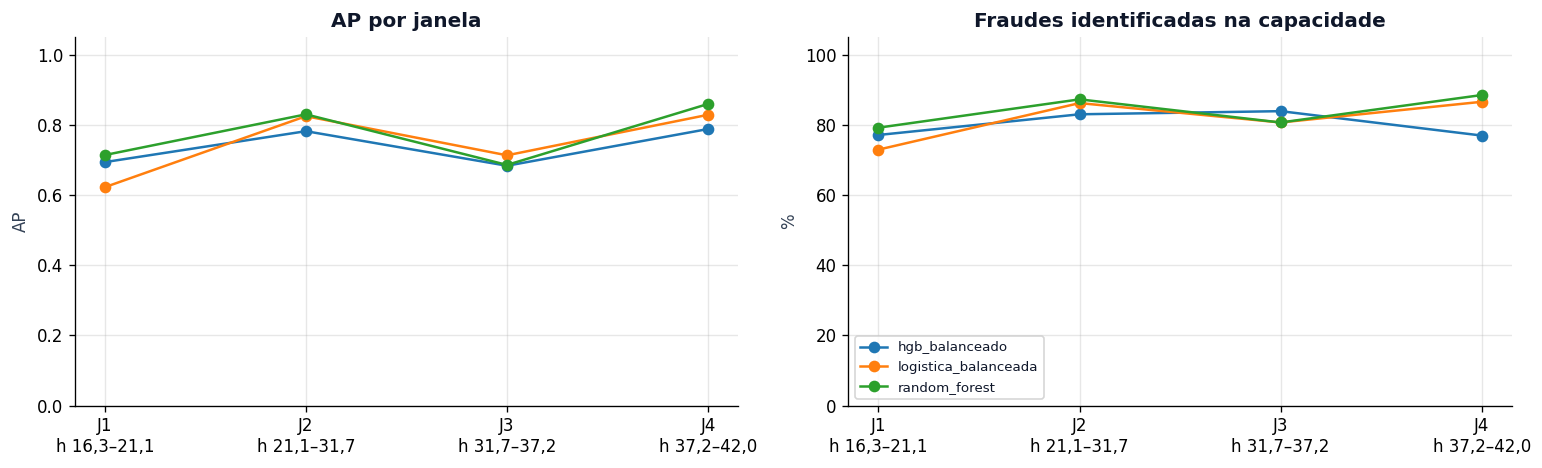

In [19]:
from sklearn.base import clone

desconhecidos = sorted(set(MODELOS_ESTABILIDADE) - set(modelos))
if desconhecidos:
    raise ValueError(f"Modelos não treinados neste notebook: {desconhecidos}")

# Período de desenvolvimento: treino + validação. O teste fica de fora.
desenvolvimento = pd.concat([treino, validacao]).sort_values("Time", kind="stable").reset_index(drop=True)
n_dev = len(desenvolvimento)
blocos = N_JANELAS_ESTABILIDADE + 2  # os dois primeiros blocos formam o primeiro treino
inicios = [desenvolvimento.iloc[int(n_dev * i / blocos)]["Time"] for i in range(2, blocos)]
fins = inicios[1:] + [np.inf]
alertas_por_hora_ref = CAPACIDADE_REVISAO / duracao_validacao_h

linhas_estabilidade = []
for j, (inicio, fim) in enumerate(zip(inicios, fins), start=1):
    treino_j = desenvolvimento[desenvolvimento["Time"] < inicio]
    janela = desenvolvimento[(desenvolvimento["Time"] >= inicio) & (desenvolvimento["Time"] < fim)]
    y_janela = janela["Class"].to_numpy()
    if y_janela.sum() == 0 or treino_j["Class"].nunique() < 2:
        raise ValueError(f"Janela {j} sem fraudes suficientes para avaliação.")
    horas = (janela["Time"].max() - janela["Time"].min()) / 3600
    capacidade = max(1, round(alertas_por_hora_ref * horas))
    for nome in MODELOS_ESTABILIDADE:
        modelo_j = clone(modelos[nome]).fit(treino_j[features], treino_j["Class"])
        score_j = modelo_j.predict_proba(janela[features])[:, 1]
        topo = np.argsort(-score_j, kind="stable")[:capacidade]
        acertos = int(y_janela[topo].sum())
        linhas_estabilidade.append({
            "janela": j,
            "horas": f"{fmt_br(janela['Time'].min() / 3600, 1)}–{fmt_br(janela['Time'].max() / 3600, 1)}",
            "modelo": nome,
            "transacoes_treino": len(treino_j),
            "transacoes": len(janela),
            "fraudes": int(y_janela.sum()),
            "alertas": capacidade,
            "AP": average_precision_score(y_janela, score_j),
            "fraudes_identificadas": acertos,
            "recall_%": 100 * acertos / y_janela.sum(),
            "precisao_%": 100 * acertos / capacidade,
        })
    print(f"Janela {j} concluída: horas {linhas_estabilidade[-1]['horas']}, "
          f"{int(y_janela.sum())} fraudes, {capacidade} alertas")

estabilidade = pd.DataFrame(linhas_estabilidade)
display(estabilidade.round(3))

resumo_estabilidade = estabilidade.groupby("modelo").agg(
    AP_media=("AP", "mean"),
    AP_desvio=("AP", "std"),
    AP_minima=("AP", "min"),
    recall_medio_pct=("recall_%", "mean"),
    recall_minimo_pct=("recall_%", "min"),
).sort_values("AP_media", ascending=False)
display(resumo_estabilidade.round(3))

posicoes = estabilidade.assign(
    posicao=estabilidade.groupby("janela")["AP"].rank(ascending=False, method="min").astype(int)
).pivot(index="modelo", columns="janela", values="posicao")
print("Posição de cada modelo por janela (1 = maior AP):")
display(posicoes)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rotulos_janela = estabilidade.drop_duplicates("janela").set_index("janela")["horas"]
for nome, grupo in estabilidade.groupby("modelo"):
    axes[0].plot(grupo["janela"], grupo["AP"], marker="o", label=nome)
    axes[1].plot(grupo["janela"], grupo["recall_%"], marker="o", label=nome)
for eixo, titulo, rotulo_y in [(axes[0], "AP por janela", "AP"),
                               (axes[1], "Fraudes identificadas na capacidade", "%")]:
    eixo.set_title(titulo)
    eixo.set_ylabel(rotulo_y)
    eixo.set_xticks(rotulos_janela.index, [f"J{j}\nh {h}" for j, h in rotulos_janela.items()])
    eixo.grid(alpha=0.3)
axes[0].set_ylim(0, 1.05)
axes[1].set_ylim(0, 105)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Exposição financeira
Os valores são apresentados na unidade monetária original do CSV. Preencha os custos na configuração para estimar o esforço operacional.

In [20]:
# Exposição financeira sinalizada, na unidade monetária original da base.
fraude = y_teste.to_numpy() == 1
alerta = pred_teste == 1
valores = teste["Amount"].to_numpy()
total_fraude = valores[fraude].sum()
identificado = valores[fraude & alerta].sum()
print(f"Valor total de fraude: {fmt_br(total_fraude)}")
print(f"Valor de fraude identificado: {fmt_br(identificado)}")
print(f"Valor de fraude sem alerta: {fmt_br(valores[fraude & ~alerta].sum())}")
print(f"Valor legítimo com alerta: {fmt_br(valores[~fraude & alerta].sum())}")
if total_fraude > 0:
    print(f"Percentual do valor de fraude identificado: {fmt_br(100 * identificado / total_fraude)}%")
print("Exposição sinalizada não equivale automaticamente a perda evitada.")

# Preencher com estimativas da operação na mesma unidade monetária.
custo_por_revisao = CUSTO_POR_REVISAO
custo_adicional_por_falso_alerta = CUSTO_ADICIONAL_POR_FALSO_ALERTA
if custo_por_revisao is not None and custo_adicional_por_falso_alerta is not None:
    falsos_alertas = (alerta & ~fraude).sum()
    custo = alerta.sum() * custo_por_revisao + falsos_alertas * custo_adicional_por_falso_alerta
    print(f"Custo operacional estimado: {fmt_br(custo)}")
else:
    print("Custo operacional pendente de parâmetros da operação.")

Valor total de fraude: 6.168,88
Valor de fraude identificado: 3.796,48
Valor de fraude sem alerta: 2.372,40
Valor legítimo com alerta: 37.700,20
Percentual do valor de fraude identificado: 61,54%
Exposição sinalizada não equivale automaticamente a perda evitada.
Custo operacional pendente de parâmetros da operação.


## Resumo executivo
Este quadro é calculado a partir da execução atual. Ele reúne o modelo selecionado, o volume de revisão, a detecção e a exposição financeira no teste exploratório.


,Resultado
Indicador,
Modelo selecionado,random_forest
Critério de seleção,AP
Transações avaliadas,42.561
Fraudes no período,52
Alertas gerados,98
Alertas por hora,"16,4"
Percentual de transações sinalizadas,"0,23%"
Fraudes identificadas,39
Fraudes sem alerta,13


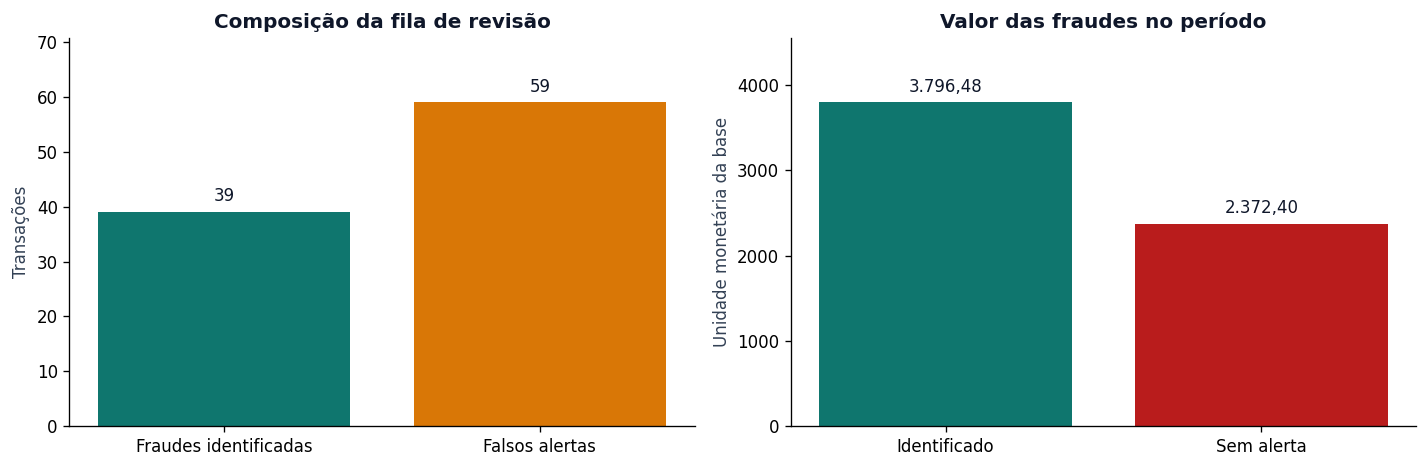

In [21]:
tn, fp, fn, tp = confusion_matrix(
    y_teste, pred_teste, labels=[0, 1]
).ravel()
quantidade_alertas = int(pred_teste.sum())
resumo = pd.DataFrame([
    ("Modelo selecionado", nome_final),
    ("Critério de seleção", CRITERIO_SELECAO),
    ("Transações avaliadas", fmt_int(len(teste))),
    ("Fraudes no período", fmt_int(y_teste.sum())),
    ("Alertas gerados", fmt_int(quantidade_alertas)),
    ("Alertas por hora", fmt_br(quantidade_alertas / duracao_teste_h, 1)),
    ("Percentual de transações sinalizadas", f"{fmt_br(100 * quantidade_alertas / len(teste))}%"),
    ("Fraudes identificadas", fmt_int(tp)),
    ("Fraudes sem alerta", fmt_int(fn)),
    ("Falsos alertas", fmt_int(fp)),
    ("Precisão", f"{fmt_br(100 * precision_score(y_teste, pred_teste, zero_division=0))}%"),
    ("Recall", f"{fmt_br(100 * recall_score(y_teste, pred_teste, zero_division=0))}%"),
    ("AP na validação", fmt_br(average_precision_score(y_validacao, score_valid), 3)),
    ("AP no teste exploratório", fmt_br(average_precision_score(y_teste, score_teste), 3)),
    ("AP nas janelas sucessivas (média | mínima)",
     f"{fmt_br(resumo_estabilidade.loc[nome_final, 'AP_media'], 3)} | "
     f"{fmt_br(resumo_estabilidade.loc[nome_final, 'AP_minima'], 3)}"
     if nome_final in resumo_estabilidade.index else "Modelo não avaliado nas janelas"),
    ("Valor de fraude identificado", fmt_br(identificado)),
    ("Valor de fraude sem alerta", fmt_br(total_fraude - identificado)),
    ("Percentual do valor identificado",
     f"{fmt_br(100 * identificado / total_fraude)}%" if total_fraude else "Sem valor de fraude"),
], columns=["Indicador", "Resultado"])
display(resumo.set_index("Indicador"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(
    ["Fraudes identificadas", "Falsos alertas"], [tp, fp],
    color=["#0f766e", "#d97706"]
)
axes[0].set_title("Composição da fila de revisão")
axes[0].set_ylabel("Transações")
axes[1].bar(
    ["Identificado", "Sem alerta"], [identificado, total_fraude - identificado],
    color=["#0f766e", "#b91c1c"]
)
axes[1].set_title("Valor das fraudes no período")
axes[1].set_ylabel("Unidade monetária da base")
for eixo, formatar in [(axes[0], fmt_int), (axes[1], fmt_br)]:
    for barra in eixo.patches:
        eixo.annotate(
            formatar(barra.get_height()),
            (barra.get_x() + barra.get_width() / 2, barra.get_height()),
            ha="center", va="bottom", xytext=(0, 4), textcoords="offset points"
        )
    eixo.margins(y=0.2)
plt.tight_layout()
plt.show()

## Diagnóstico das fraudes sem alerta
O ranking identifica casos próximos do corte e casos com scores baixos. As hipóteses decorrentes desta análise devem ser verificadas em novos dados.

In [22]:
analise = teste.copy()
analise["score"]   = score_teste
analise["alerta"]  = pred_teste
analise["posicao"] = analise["score"].rank(ascending=False, method="first").astype(int)
analise["hora"]    = (analise["Time"] // 3600) % 24

fraudes_teste = analise[analise["Class"] == 1].copy()
fraudes_teste["grupo"] = np.where(fraudes_teste["alerta"] == 1, "pegas", "perdidas")

print(f"Alertas gerados: {pred_teste.sum()} (posições 1 a {pred_teste.sum()} no ranking)\n")
print(fraudes_teste.loc[fraudes_teste["grupo"] == "perdidas",
                        ["hora", "Amount", "score", "posicao"]]
      .sort_values("posicao"))

Alertas gerados: 98 (posições 1 a 98 no ranking)

        hora   Amount     score  posicao
271500  21.0    12.31  0.072698      107
244645  18.0   357.95  0.063047      119
250968  19.0     7.06  0.049693      161
274961  22.0   634.30  0.036517      215
250958  19.0     3.14  0.036505      216
273358  22.0     0.00  0.009939     1015
262115  20.0     1.00  0.006662     1284
248322  18.0  1096.99  0.006655     1329
280611  23.0    42.53  0.006611     1890
253404  19.0   187.11  0.003308     4103
244437  18.0     2.47  0.000000     8475
253455  19.0     7.59  0.000000    16303
275040  22.0    19.95  0.000000    35089


## Interpretação do modelo
A permutação mede a queda de AP na validação ao embaralhar cada variável. A análise utiliza três repetições. Variáveis correlacionadas podem compartilhar informação. O desvio entre repetições descreve a variabilidade do embaralhamento.

In [23]:
from sklearn.inspection import permutation_importance

print(fraudes_teste.groupby("grupo")["Amount"].describe())
print(pd.crosstab(fraudes_teste["hora"], fraudes_teste["grupo"]))
# Validação completa, preservando os raros exemplos de fraude.
# Uma tarefa por vez evita paralelismo aninhado com a Random Forest.
resultado_importancia = permutation_importance(
    modelo_final, x_validacao, y_validacao,
    scoring="average_precision", n_repeats=3,
    random_state=SEMENTE, n_jobs=1
)
importancias = pd.Series(
    resultado_importancia.importances_mean, index=features, name="queda_media_AP"
).sort_values(ascending=False)
display(pd.DataFrame({
    "queda_media_AP": importancias,
    "desvio_repeticoes": pd.Series(resultado_importancia.importances_std, index=features)
}).loc[importancias.index].round(4))


          count        mean         std  min   25%    50%     75%      max
grupo                                                                     
pegas      39.0   97.345641  253.731873  0.0  0.77   4.69   67.81  1504.93
perdidas   13.0  182.492308  333.966054  0.0  3.14  12.31  187.11  1096.99
grupo  pegas  perdidas
hora                  
18.0      15         3
19.0       8         4
20.0       9         1
21.0       1         1
22.0       3         3
23.0       3         1


,queda_media_AP,desvio_repeticoes
V4,0.0469,0.0006
V14,0.0157,0.0013
V11,0.0101,0.0043
V7,0.0079,0.0013
V12,0.0061,0.0006
V1,0.0050,0.0016
V17,0.0046,0.0020
V10,0.0045,0.0032
V16,0.0045,0.0008
V21,0.0044,0.0008


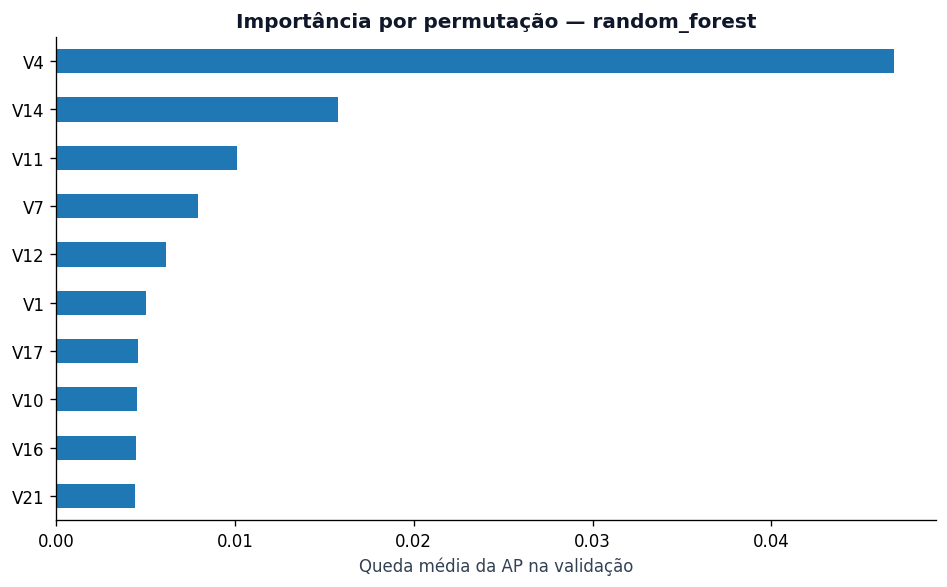

In [24]:
importancias.head(10).sort_values().plot.barh(
    title=f"Importância por permutação — {nome_final}", figsize=(8, 5)
)
plt.xlabel("Queda média da AP na validação")
plt.tight_layout()
plt.show()


## Distribuições por grupo e casos de maior valor
Compare medianas e médias das variáveis mais importantes. A tabela dos maiores casos perdidos mostra se outros modelos os sinalizariam com seus próprios cortes de validação.

In [25]:
principais = importancias.head(8).index.tolist()
grupos = analise.assign(grupo=np.where(
    analise["Class"] == 0, "legitimas",
    np.where(analise["alerta"] == 1, "fraudes_identificadas", "fraudes_perdidas")
))
por_grupo = grupos.groupby("grupo")[principais]
display(pd.concat(
    {"mediana": por_grupo.median().T, "média": por_grupo.mean().T}, axis=1
).round(2))
# Diagnóstico exploratório dos casos de maior exposição.
maiores_perdidas = fraudes_teste.loc[
    fraudes_teste["grupo"] == "perdidas"
].nlargest(3, "Amount")
diagnostico = maiores_perdidas[["Time", "Amount", "score", "posicao"]].copy()
if not maiores_perdidas.empty:
    for nome, modelo in modelos.items():
        if nome == "dummy":
            continue
        score_casos = modelo.predict_proba(maiores_perdidas[features])[:, 1]
        corte = np.sort(scores[nome])[::-1][k - 1]
        diagnostico[f"{nome}_score"] = score_casos
        diagnostico[f"{nome}_alertaria"] = score_casos >= corte
display(diagnostico.round(4))

mediana                                            média  \
grupo fraudes_identificadas fraudes_perdidas legitimas fraudes_identificadas   
V4                     5.10             1.09     -0.37                  4.51   
V14                   -8.40            -1.43     -0.03                 -8.54   
V11                    3.48             0.49     -0.33                  3.28   
V7                    -2.69             0.72      0.16                 -2.42   
V12                   -5.27             0.14      0.22                 -5.25   
V1                    -1.20             0.20      0.09                 -2.06   
V17                   -3.71             0.90     -0.17                 -3.85   
V10                   -4.03             0.23     -0.10                 -4.15   

                                  
grupo fraudes_perdidas legitimas  
V4                1.93     -0.20  
V14              -1.09     -0.13  
V11               0.33     -0.31  
V7               -0.10      0.11  
V12               0.12      0.20  
V1               -0.31      0.29  
V17               0.76     -0.06  
V10               0.05      0.01

,Time,Amount,score,posicao,logistica_score,logistica_alertaria,logistica_balanceada_score,logistica_balanceada_alertaria,hgb_score,hgb_alertaria,hgb_balanceado_score,hgb_balanceado_alertaria,random_forest_score,random_forest_alertaria
248322,154309.0,1096.99,0.0067,1329,0.0003,False,0.1106,False,0.0008,False,0.0130,False,0.0067,False
274961,166831.0,634.30,0.0365,215,0.0002,False,0.2187,False,0.0008,False,0.4391,False,0.0365,False
244645,152802.0,357.95,0.0630,119,0.0019,False,0.4497,False,0.3163,True,0.6266,False,0.0630,False


## Próximos critérios de validação

| Tema | Evidência a obter |
|---|---|
| Reprodução | Execução integral em kernel limpo com versões registradas |
| Estabilidade | Janelas sucessivas avaliadas no desenvolvimento; falta confirmar em um novo período reservado |
| Capacidade | Volume de alertas compatível com o tempo disponível da equipe |
| Exposição financeira | Valor identificado por capacidade de revisão e por período |
| Custos | Estimativas de revisão e impacto dos falsos alertas |
| Qualidade da base | Confirmação da origem, duplicatas e disponibilidade das variáveis |
| Uso de probabilidades | Avaliação de calibração em dados separados |

A alteração de modelo, critério ou limiar deve ser registrada junto com a justificativa. A confirmação em novos períodos permitirá avaliar a aplicação operacional.